In [3]:
import sys
sys.path.append("../")
from collections import defaultdict

import pyarrow.feather as feather
import numpy as np
import itertools
from pathlib import Path
from utils import *
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, RobustScaler

from tqdm.auto import tqdm
from astropy.stats import bayesian_blocks

import seaborn as sns
sns.set_context("notebook", font_scale=1.2)
colors = sns.color_palette("muted")

import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams.update({"font.size" : 15,
                     "figure.dpi" : 100, 
                     "grid.alpha" : 0.3, 
                     "axes.grid": False, 
                     "axes.axisbelow" : True,
                     "figure.figsize":(8,6),
                     "mathtext.fontset":"cm",
                     "xtick.labelsize": 14,
                     "ytick.labelsize": 14,
                     "axes.labelsize": 16, 
                     "legend.fontsize": 13.5})
plt.rc("text", usetex=False)
plt.rc("font", family="serif")

In [4]:
DATA_DIR = Path("../data/sweep_2026_04_01_1556/")
sim_df = feather.read_feather(DATA_DIR / "simulations.arrow")
node_df = feather.read_feather(DATA_DIR / "nodes.arrow")
cascade_df = feather.read_feather(DATA_DIR / "cascades.arrow")
print("Simulations:", sim_df.shape)
print("Nodes:", node_df.shape)

Simulations: (50000, 13)
Nodes: (15000000, 15)


### Compute Normalized Agent Payoffs

In [5]:
# Precompute per-sim fake/true counts
sim_counts = cascade_df.groupby("global_sim_id")["is_fake"].agg(
    num_fake="sum"
).reset_index()
sim_counts["num_true"] = 1000 - sim_counts["num_fake"]

# Merge counts into node_df
node_df = node_df.merge(sim_counts, on="global_sim_id", how="left")

# Compute veracity vectorized
node_df["veracity"] = (node_df["true_shares"] / node_df["num_true"]) - \
                      (node_df["fake_shares"] / node_df["num_fake"])

# Drop helper columns
node_df.drop(columns=["num_fake", "num_true"], inplace=True)

In [6]:
node_df["veracity_scaled_by_messages"] = node_df["veracity"] * (node_df["true_shares"] + node_df["fake_shares"])

In [7]:
# proportion of all agents who never had any option to do anything
print(round(len(node_df[(node_df["best_payoff"]==0)&(node_df["worst_payoff"]==0)]) / len(node_df), 3))

0.009


In [8]:
# proportion of all agents with zero final payoff
print(round(len(node_df[(node_df["payoff"]==0)]) / len(node_df), 3))

0.352


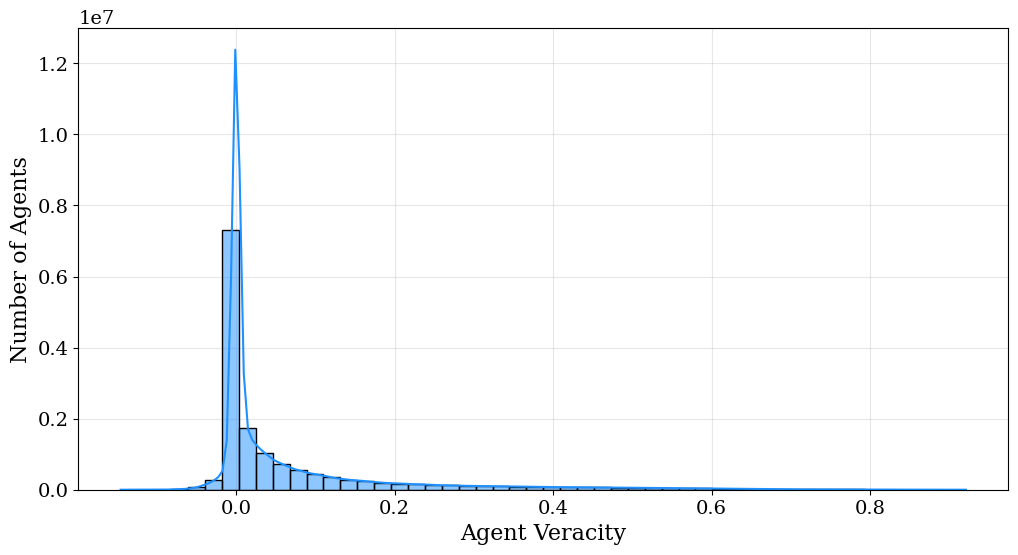

In [9]:
plt.figure(figsize=(12, 6))
sns.histplot(node_df['veracity'], bins=50, kde=True, color='dodgerblue')
plt.xlabel("Agent Veracity")
plt.ylabel("Number of Agents")
plt.grid()
plt.show()

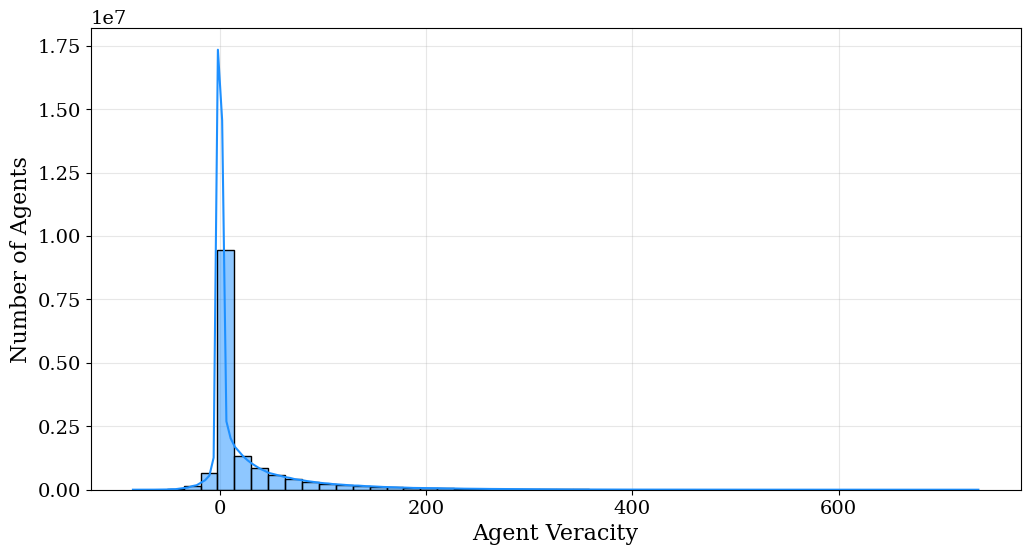

In [10]:
plt.figure(figsize=(12, 6))
sns.histplot(node_df['veracity_scaled_by_messages'], bins=50, kde=True, color='dodgerblue')
plt.xlabel("Agent Veracity")
plt.ylabel("Number of Agents")
plt.grid()
plt.show()

### Compute Sen Welfare For Each Simulation

In [11]:
# compute sen welfare per simulation
sen_values = (
    node_df
    .groupby("global_sim_id")["veracity"]
    .apply(lambda x: sen_welfare(x.values))
    .reset_index()
    .rename(columns={"veracity": "sen_welfare"})
)

sim_df = sim_df.merge(sen_values, on="global_sim_id")

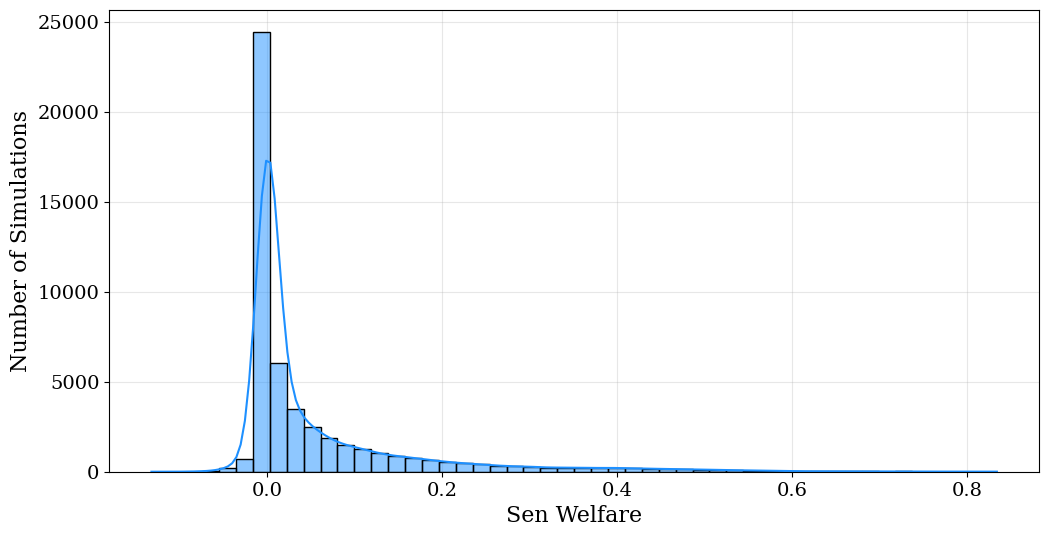

In [12]:
plt.figure(figsize=(12, 6))
sns.histplot(sim_df['sen_welfare'], bins=50, kde=True, color='dodgerblue')
plt.xlabel("Sen Welfare")
plt.ylabel("Number of Simulations")
plt.grid()
plt.show()

### Heatmaps for veracity differential and sen welfare over parameter space

In [13]:
# bin resolution
N_BINS = 10

param_cols = [
    "v_cost",
    "loss",
    "tpr",
    "fpr",
    "p_fake"
]

param_pairs = list(itertools.combinations(param_cols, 2))
len(param_pairs)

10

In [14]:
def plot_hexbin_grid(df, value_col, title, bins=N_BINS):
    fig, axes = plt.subplots(2, 5, figsize=(20, 7.5))
    axes = axes.flatten()

    for ax, (xparam, yparam) in zip(axes, param_pairs):
        hb = ax.hexbin(
            df[xparam],
            df[yparam],
            C=df[value_col],
            reduce_C_function=np.mean,
            gridsize=bins,
            cmap="viridis"
        )
        ax.set_xlabel(xparam)
        ax.set_ylabel(yparam)
        ax.set_title(f"{xparam} vs {yparam}")

    fig.suptitle(title, fontsize=18)
    fig.tight_layout()
    cbar = fig.colorbar(hb, ax=axes.tolist())
    cbar.set_label(value_col)
    plt.show()

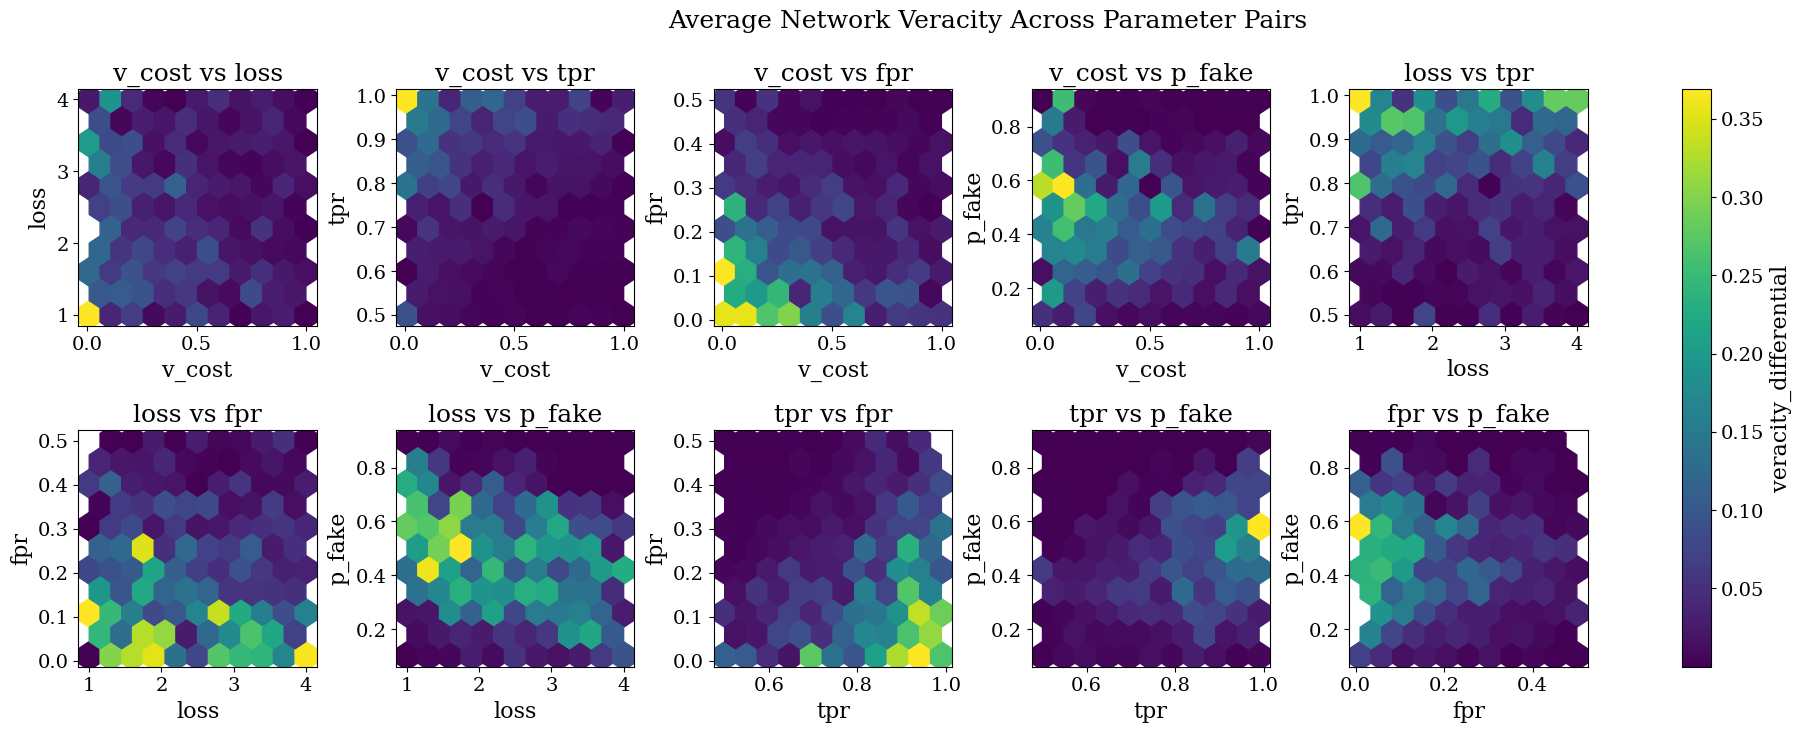

In [15]:
plot_hexbin_grid(
    sim_df,
    value_col="veracity_differential",
    title="Average Network Veracity Across Parameter Pairs"
)

### Average Network Veracity Versus Average Sen Welfare

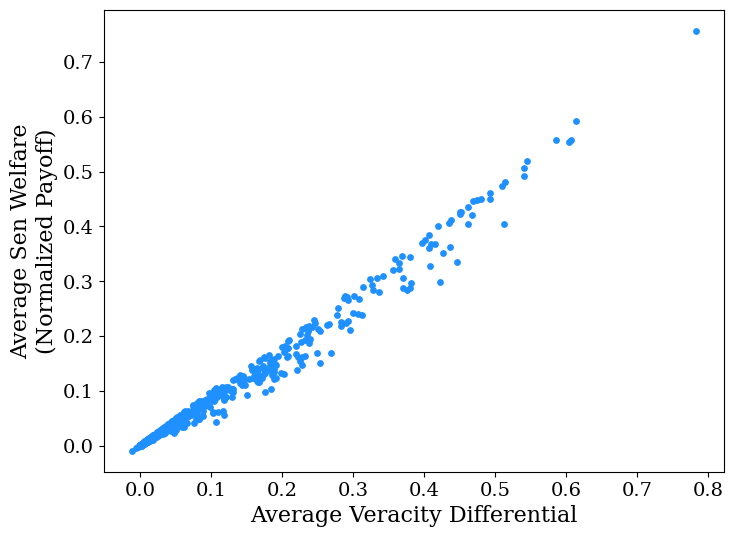

In [17]:
plt.scatter(
    sim_df.groupby("lhs_id").mean()["veracity_differential"],
    sim_df.groupby("lhs_id").mean()["sen_welfare"],
    color="dodgerblue",
    s=15
)

plt.xlabel("Average Veracity Differential")
plt.ylabel("Average Sen Welfare\n(Normalized Payoff)")
plt.show()

### Average Average Verification Rate Versus Veracity Differential

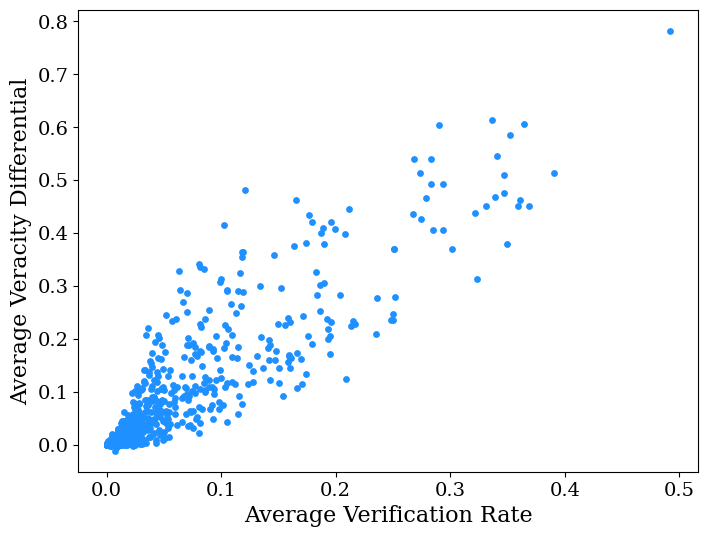

In [18]:
plt.scatter(
    sim_df.groupby("lhs_id").mean()["avg_verify_rate"],
    sim_df.groupby("lhs_id").mean()["veracity_differential"],
    color="dodgerblue",
    s=15
)

plt.xlabel("Average Verification Rate")
plt.ylabel("Average Veracity Differential")
plt.show()

### True and Fake Cascade Sizes

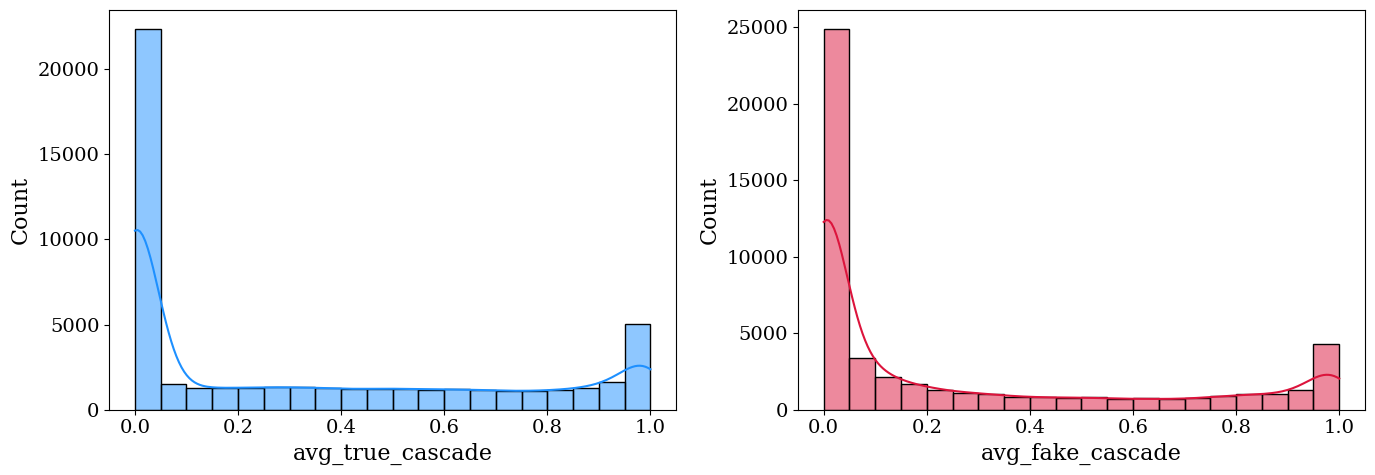

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))

sns.histplot(sim_df["avg_true_cascade"], bins=20, kde=True, color="dodgerblue", ax=axes[0])
sns.histplot(sim_df["avg_fake_cascade"], bins=20, kde=True, color="crimson", ax=axes[1])

fig.tight_layout()
plt.show()

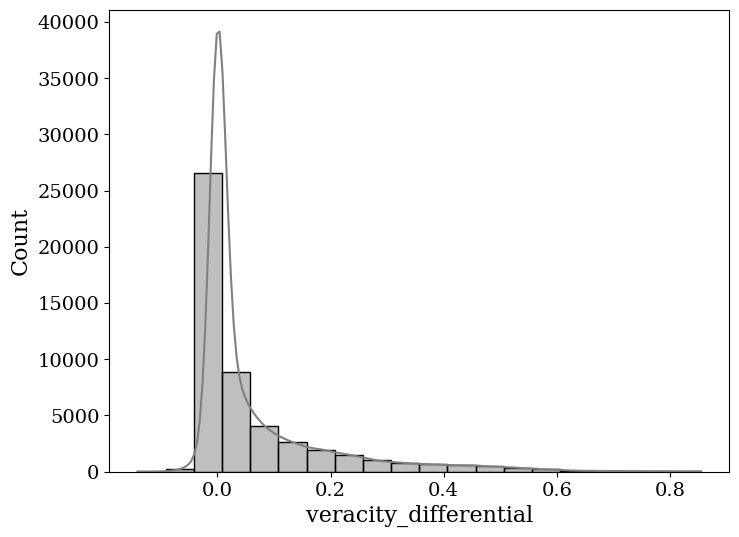

In [20]:
sns.histplot(sim_df["veracity_differential"], bins=20, kde=True, color="grey")
plt.show()

### Agent belief of global truth prevalence vs. actual

In [21]:
# Calculate true prevalence for all rows
node_df = node_df.copy()
node_df['true_prevalence'] = node_df['true_alpha'] / (node_df['true_alpha'] + node_df['true_beta'])

# Merge node_df with sim_df to get p_true in one shot
merged = node_df.merge(
    sim_df[['global_sim_id', 'p_fake']],
    on='global_sim_id',
    how='left'
)

# Compute p_true
merged['p_true'] = 1 - merged['p_fake']

# Group by p_true and sum true_prevalence
data = merged.groupby('p_true')['true_prevalence'].mean().to_dict()

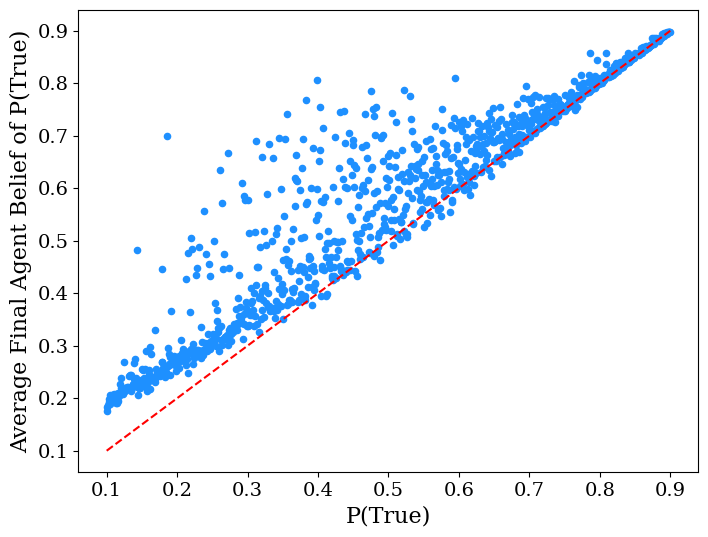

In [22]:
plt.scatter(
    list(data.keys()),
    list(data.values()),
    color="dodgerblue",
    s=20
)
plt.xlabel("P(True)")
plt.ylabel("Average Final Agent Belief of P(True)")

plt.plot(
    np.linspace(0.1, 0.9, 2),
    np.linspace(0.1, 0.9, 2),
    color="red",
    linestyle="dashed"
)

plt.show()

### Discard Rate

In [23]:
discard_rate = []
for _, group in node_df.groupby("global_sim_id"):
    D = (1000 - group["true_shares"] - group["fake_shares"]) / 1000
    discard_rate.append(np.mean(D))

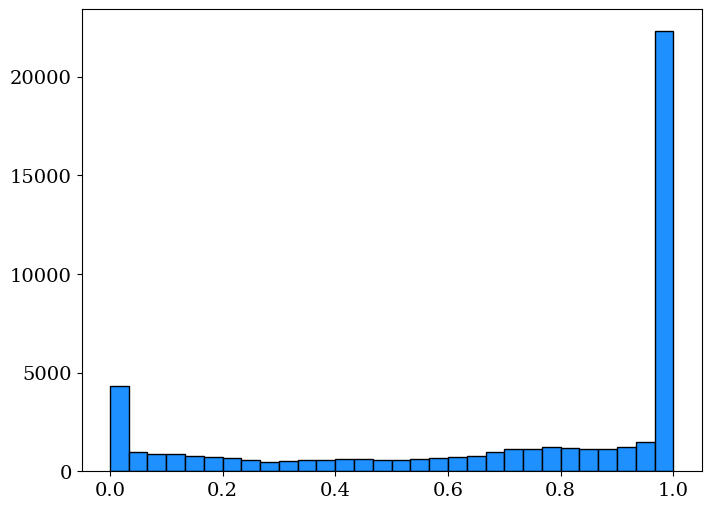

In [24]:
plt.hist(discard_rate, color="dodgerblue", edgecolor="k", bins=30)
plt.show()

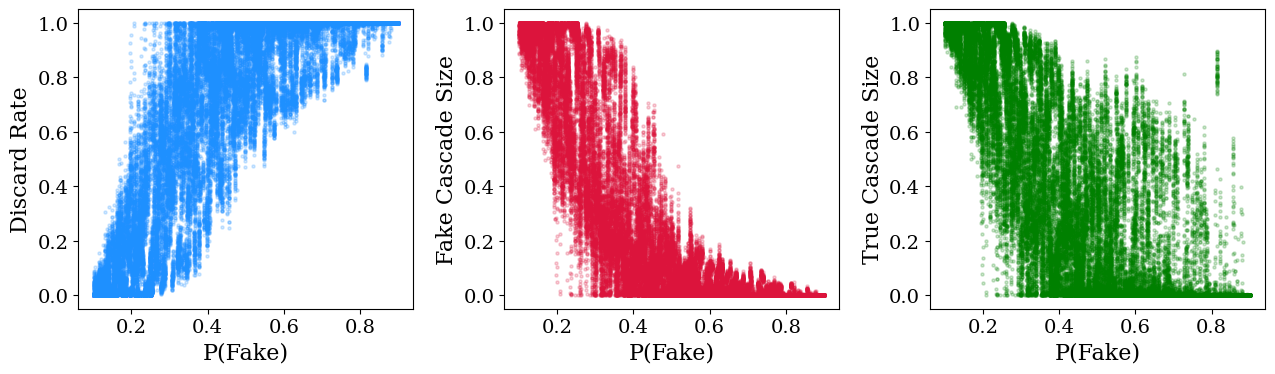

In [25]:
fig, axs = plt.subplots(1, 3, figsize=(13,4))

axs[0].scatter(
    sim_df["p_fake"],
    discard_rate,
    s=5,
    color="dodgerblue",
    alpha=0.2
)
axs[0].set_ylabel("Discard Rate")

axs[1].scatter(
    sim_df["p_fake"],
    sim_df["avg_fake_cascade"].values,
    s=5,
    color="crimson",
    alpha=0.2
)
axs[1].set_ylabel("Fake Cascade Size")

axs[2].scatter(
    sim_df["p_fake"],
    sim_df["avg_true_cascade"].values,
    s=5,
    color="green",
    alpha=0.2
)
axs[2].set_ylabel("True Cascade Size")

for i in range(3):
    axs[i].set_xlabel("P(Fake)")

fig.tight_layout()
plt.show()

### Regimes

In [26]:
vd = sim_df["veracity_differential"].values
sw = sim_df["sen_welfare"].values

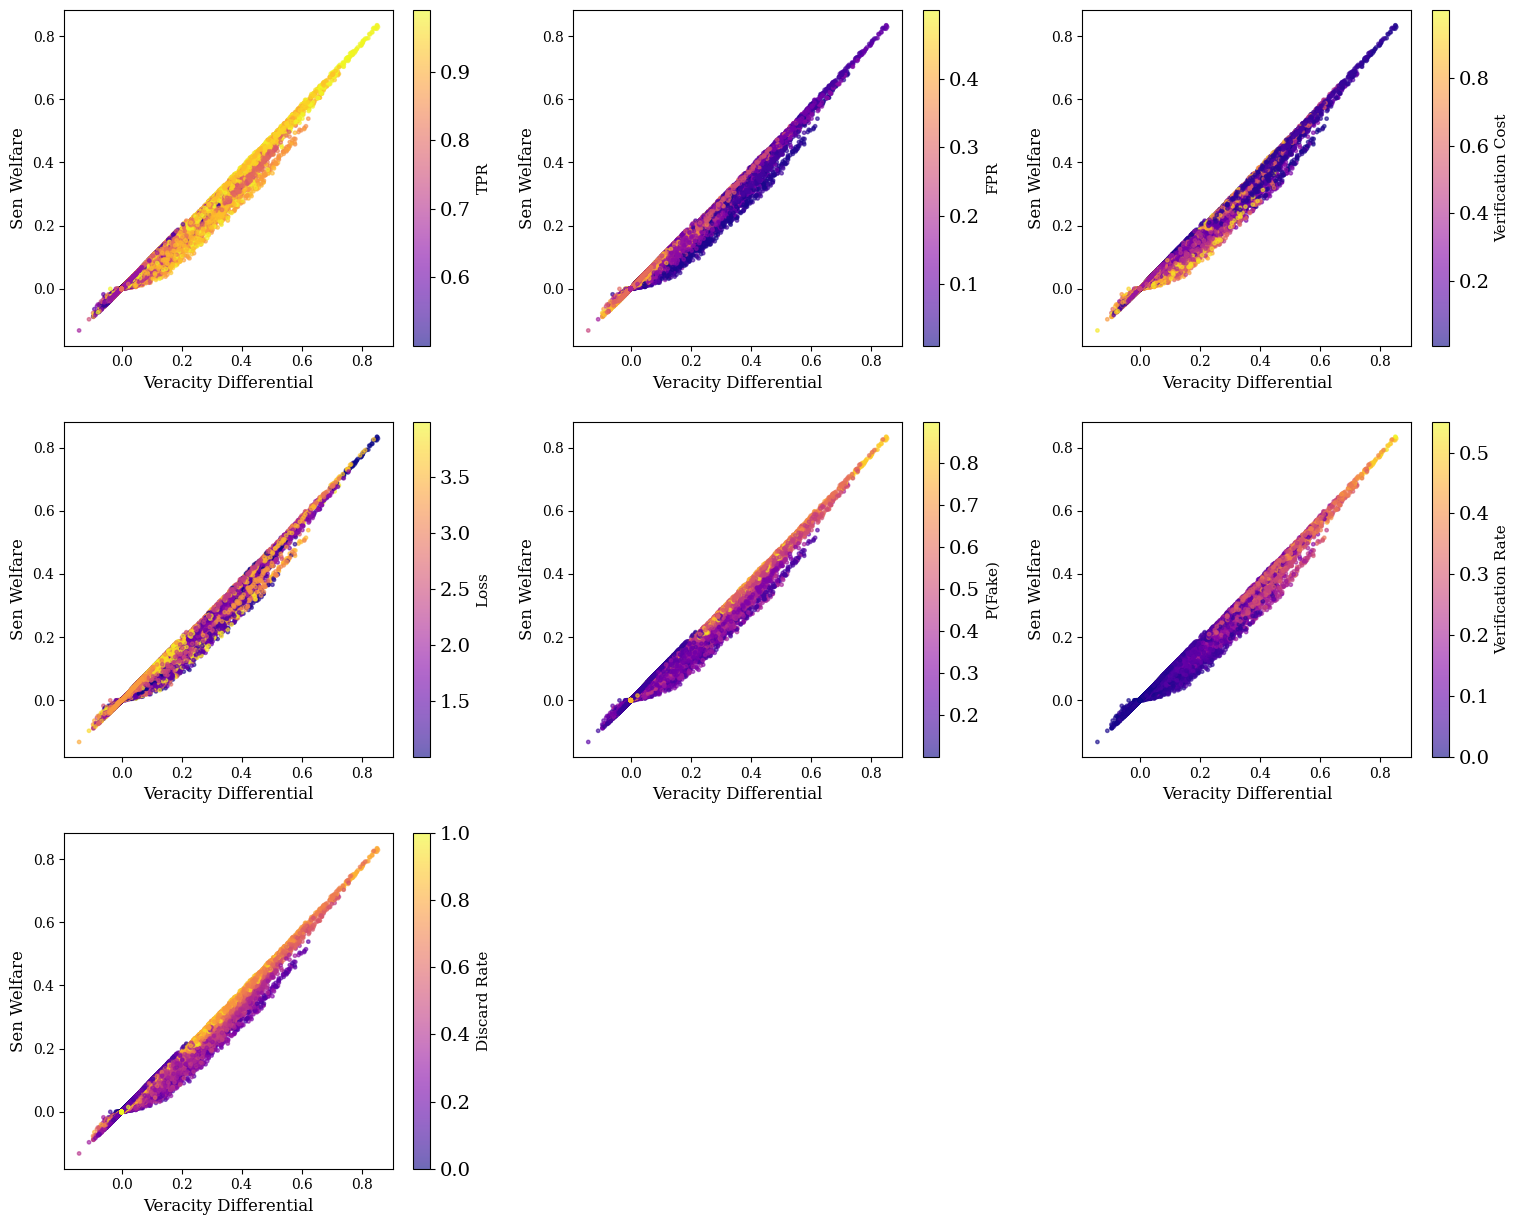

In [27]:
fig, axes = plt.subplots(3, 3, figsize=(15.5, 12.5))

# Flatten axes for easy iteration
axes = axes.flatten()

# List of (data, label) pairs
color_vars = [
    (sim_df["tpr"].values, "TPR"),
    (sim_df["fpr"].values, "FPR"),
    (sim_df["v_cost"].values, "Verification Cost"),
    (sim_df["loss"].values, "Loss"),
    (sim_df["p_fake"].values, "P(Fake)"),
    (sim_df["avg_verify_rate"].values, "Verification Rate"),
    (discard_rate, "Discard Rate"),
]

# Loop through variables and plot
for i, (cvals, label) in enumerate(color_vars):
    ax = axes[i]
    sc = ax.scatter(
        vd, sw,
        c=cvals,
        cmap="plasma",
        alpha=0.6,
        s=6,
        rasterized=True
    )
    cb = fig.colorbar(sc, ax=ax)
    cb.set_label(label, fontsize=11)

    ax.set_xlabel("Veracity Differential", fontsize=12)
    ax.set_ylabel("Sen Welfare", fontsize=12)
    ax.tick_params(labelsize=10)

# Turn off unused subplots
for j in range(len(color_vars), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

In [28]:
vars_ = ["tpr", "fpr", "v_cost", "loss", "p_fake", "veracity_differential"]

scaler = MinMaxScaler()
sim_df_scaled = sim_df.copy()
sim_df_scaled[vars_] = scaler.fit_transform(sim_df[vars_])

n_regimes = 4

sim_df_scaled["welfare_regime"] = pd.qcut(
    sim_df_scaled["sen_welfare"], 
    q=n_regimes, 
    labels=list(range(n_regimes))
)

grouped_scaled = sim_df_scaled.groupby("welfare_regime")[vars_].mean()

/var/folders/mz/n_rzzjx149d19ncnxglpf7n40000gn/T/ipykernel_26202/2246843326.py:15: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_scaled = sim_df_scaled.groupby("welfare_regime")[vars_].mean()


In [29]:
def radar_plot(ax, values, labels, title):
    N = len(labels)
    angles = np.linspace(0, 2*np.pi, N, endpoint=False).tolist()
    values = values.tolist()
    
    # close the loop
    values += values[:1]
    angles += angles[:1]

    ax.plot(angles, values, linewidth=2)
    ax.fill(angles, values, alpha=0.25)

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(labels, fontsize=10)

    ax.set_yticks([])
    # ax.set_title(title, fontsize=14, pad=20)

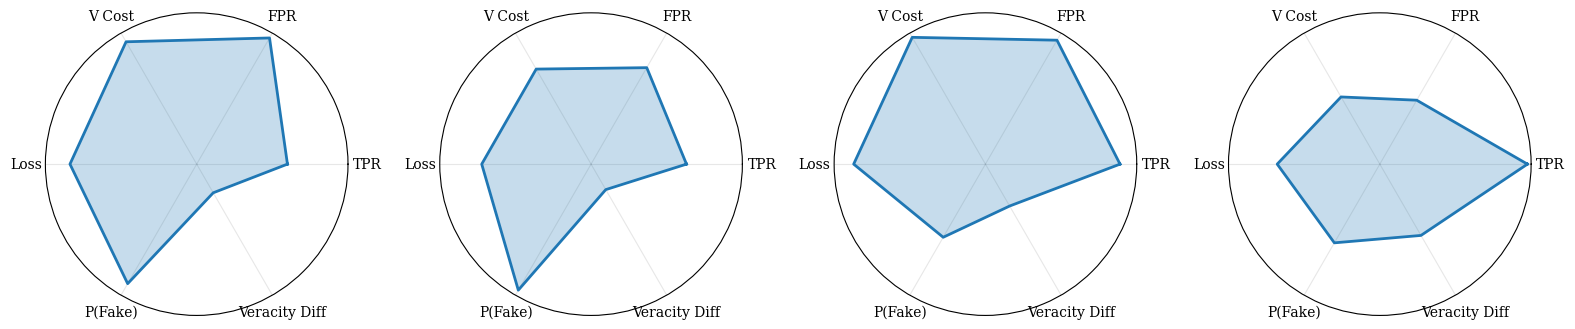

In [30]:
fig, axes = plt.subplots(1, n_regimes, figsize=(16, 5), subplot_kw=dict(polar=True))

labels = ["TPR", "FPR", "V Cost", "Loss", "P(Fake)", "Veracity Diff"]

for ax, regime in zip(axes, grouped_scaled.index):
    radar_plot(
        ax,
        grouped_scaled.loc[regime],
        labels,
        title=f"Welfare Regime #{regime}"
    )

plt.tight_layout()
plt.show()